# Introduction to Machine Learning -- MC886
# Assignment 2 - Model Selection and Regularization

**Professor:** Marcelo da Silva Reis  
**PED:** Heigon Soldera

In [51]:
# Please, enter your name and RA number in the lines below:
print(f"{'Álvaro Brandão de Carvalho':32}", "|", "195033")
print(f"{'Henrique Cazarim Meirelles Alves':32}", "|", "24763")

Álvaro Brandão de Carvalho       | 195033
Henrique Cazarim Meirelles Alves | 24763


---

## Objective

This assignment investigates the effects of overfitting in different data regimes
and test conditions.
The goal is to understand the different results of regularization when data
availability changes, and how they impact the generalization across **three**
different distributions: the one used for training, the clean one, and a
corruption the model has never seen.

### Guidelines

> Please read these guidelines carefully.

1. Questions can be answered in English or in Portuguese.

2. Use data visualization as a primary tool for understanding the problem. Inspect the training data, corrupted inputs, and model behavior. When an assumption is uncertain, verify it empirically through plots.

3. The provided code serves only as a reference. Modifications are allowed, including changes to functions and the introduction of new components. Code clarity and organization are required.

4. The use of generative AI tools (e.g., ChatGPT, GitHub Copilot, DeepSeek, LLaMA) is permitted strictly for implementation support. The use of AI for interpreting, analyzing, or discussing experimental results is discouraged. Submissions must include:
	- A declaration of which models were used.
	- The prompts that generated any incorporated code.

5. Do not hesitate to reach out to the PED/PAD via Discord.

### About the Dataset

This assignment uses the [MNIST](https://web.archive.org/web/20240213122836/http://yann.lecun.com/exdb/mnist/) dataset, a standard benchmark for image classification. It consists of 28×28 grayscale images of handwritten digits (0–9), where each pixel encodes an intensity value in [0, 255].

MNIST is useful here because it is simple enough that a linear model can do well on it, which means the learned weights are directly interpretable as images, where each weight corresponds to the influence of each pixel.

To study robustness and distribution shift, the images were corrupted with one of the corruptions of [MNIST-C](https://github.com/google-research/mnist-c) (Mu & Gilmer, 2019). Which corruption it is, is for you to find out in Part 1.

The training set consists entirely of corrupted images. The test set contains **three splits** of the same 10,000 test images:
- `test_corrupted`: corrupted test images (same corruption as training).
- `test_clean`: the original, uncorrupted MNIST test images.
- `test_impulse`: the test images with a **different** corruption, impulse (salt-and-pepper) noise, never seen during training.

Performance on `test_corrupted` measures how well the model learned the training task.
Performance on `test_clean` measures how well the model learned digit recognition.
Performance on `test_impulse` measures whether the robustness acquired during training transfers to a corruption the model was never exposed to.

Your job is to train three different models, each one with different number of
available samples:
- Full-data (60000 samples)
- Partial-data (10000 samples)
- Scarce-data (1000 samples)

Finding the best combination of hyper-parameter for each one of them.

In [52]:
from typing import Any

from numpy.typing import NDArray
import numpy as np
import pandas as pd
import random

import torch
import torch.nn as nn
from torch import optim

import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import StandardScaler

# Set random seeds for reproducibility.
# Do not tune this number
# Re-run the notebook from the beginning before submitting.
seed = 42
torch.random.manual_seed(seed)
np.random.seed(seed)
random.seed(seed)

In [53]:
# The dataset is available in the classroom assignment.
# Ensure you have downloaded it and placed it alongside this notebook.

# DO NOT change this cell

def subsample_dataset(
	X: NDArray[Any], y: NDArray[Any], n: int
) -> tuple[NDArray[Any], NDArray[Any]]:
	n_samples = len(y)

	idxs = np.random.choice(
		n_samples, size=n, replace=False
	)

	return X[idxs], y[idxs]

DATA_DIR = "data_2s2026"

X_full = np.load(f"{DATA_DIR}/train/train_images.npy")
y_full = np.load(f"{DATA_DIR}/train/train_labels.npy")

X_partial, y_partial = subsample_dataset(X_full, y_full, 10_000)
X_scarce, y_scarce = subsample_dataset(X_full, y_full, 1_000)

print(f"Full-data set: {X_full.shape[0]} samples")
print(f"Partial-data set: {X_partial.shape[0]} samples")
print(f"Scarce-data set: {X_scarce.shape[0]} samples")

Full-data set: 60000 samples
Partial-data set: 10000 samples
Scarce-data set: 1000 samples


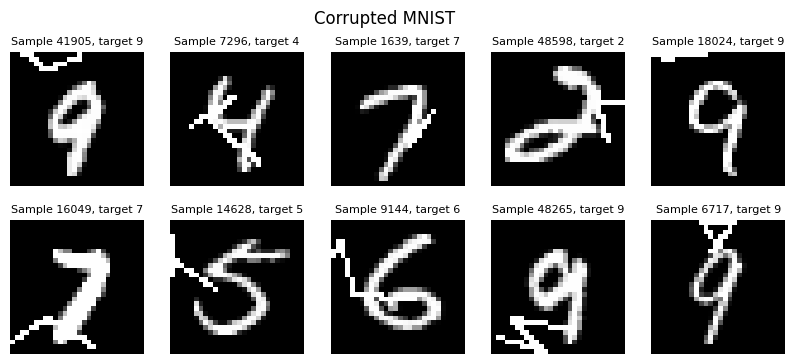

In [54]:
n_cols = 5
n_rows = 2

fig, axs = plt.subplots(nrows=n_rows, ncols=n_cols, figsize=(2*n_cols, 2*n_rows))

fig.suptitle("Corrupted MNIST")

for i in range(n_rows):
	for j in range(n_cols):
		ax = axs[i, j]
		idx = random.randint(0, len(X_full)-1)

		ax.set_title(f"Sample {idx}, target {y_full[idx]}", fontsize=8)
		ax.imshow(X_full[idx], cmap='grey')
		ax.set_axis_off()

---

## Part 1. Data Analysis and Preprocessing

### 1.1 Exploring the corruption

**(1.0 point)**

Before any modeling, understand what the corruption actually does to the data.

Is the corruption random per-pixel noise, or is it a structured perturbation?
Explore the **training** dataset, understand the distribution and the effects of the introduced
noise. Useful tools are per-class mean images, per-pixel statistics (e.g., how often each
pixel is saturated at 255), and looking at many individual samples side by side.

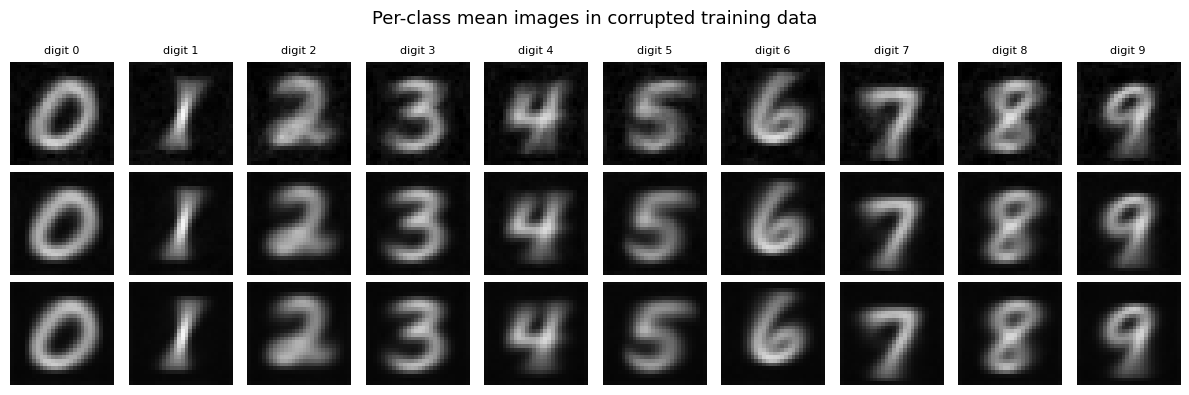

In [55]:
data_regimes = {
	"Scarce": (X_scarce, y_scarce),
	"Partial": (X_partial, y_partial),
	"Full": (X_full, y_full),
}

fig, axs = plt.subplots(len(data_regimes), 10, figsize=(4*len(data_regimes), 4))
for digit in range(10):
	axs[0, digit].set_title(f"digit {digit}", fontsize=8)

for i, name in enumerate(data_regimes):
	X, y = data_regimes[name]


	for digit in range(10):
		mask = (y == digit)
		mean_img = X[mask].mean(axis=0)
		axs[i, digit].imshow(mean_img, cmap="gray", vmin=0, vmax=255)
		axs[i, digit].axis("off")

	axs[i, 0].set_ylabel(f"{name}-data regime", fontsize=9)

plt.suptitle("Per-class mean images in corrupted training data", fontsize=13)
plt.tight_layout()
plt.show()

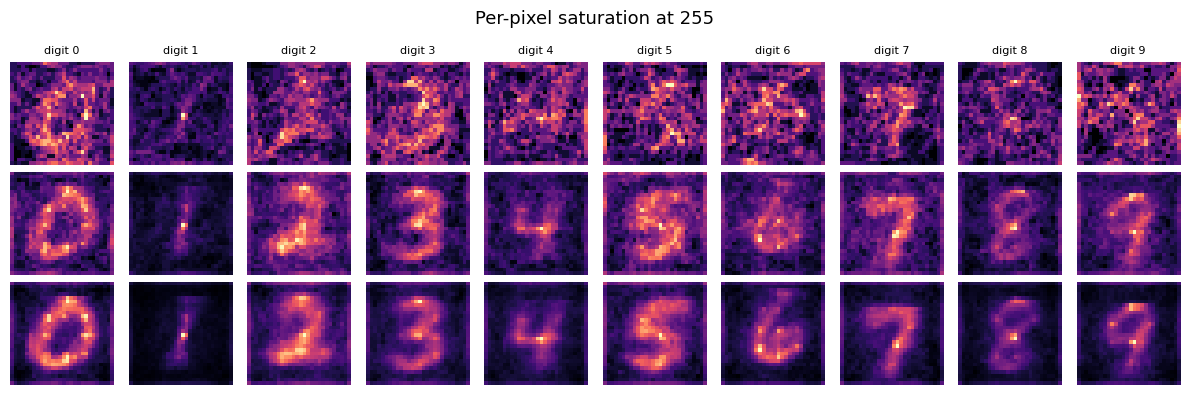

In [56]:
fig, axs = plt.subplots(len(data_regimes), 10, figsize=(4*len(data_regimes), 4))
for digit in range(10):
	axs[0, digit].set_title(f"digit {digit}", fontsize=8)

for i, name in enumerate(data_regimes):
	X, y = data_regimes[name]


	for digit in range(10):
		mask = (y == digit)
		freq_img = (X[mask] == 255).mean(axis=0)
		axs[i, digit].imshow(freq_img, cmap="magma")
		axs[i, digit].axis("off")

	axs[i, 0].set_ylabel(f"{name}-data regime", fontsize=9)

plt.suptitle("Per-pixel saturation at 255", fontsize=13)
plt.tight_layout()
plt.show()

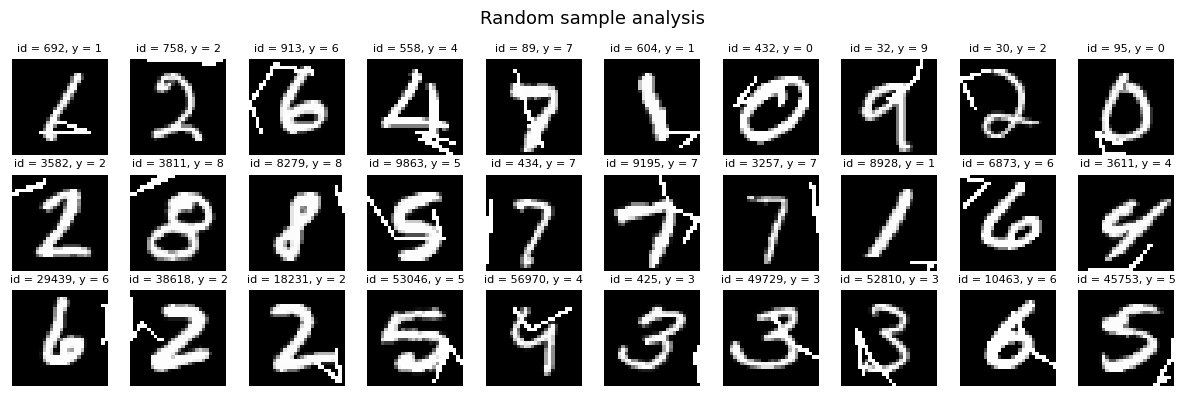

In [57]:
fig, axs = plt.subplots(len(data_regimes), 10, figsize=(4*len(data_regimes), 4))

for i, name in enumerate(data_regimes):
	X, y = data_regimes[name]

	for j in range(10):
		ax = axs[i, j]
		idx = random.randint(0, len(X)-1)

		ax.set_title(f"id = {idx}, y = {y[idx]}", fontsize=8)
		ax.imshow(X[idx], cmap='grey')
		ax.set_axis_off()

plt.suptitle("Random sample analysis", fontsize=13)
plt.tight_layout()
plt.show()

> **Question 1.1**
>
> (a) Describe the corruption. Is it random and per-sample, or is it systematic and shared across images? Does it vary across digit classes?
>
> (b) Why does the corruption turn into a faint, nearly uniform background in the per-class mean images? What does that tell you about using mean images to diagnose a corruption?
>
> (c) The corruption is made of strokes, and digits are also made of strokes. Which digits do you expect to be most easily confused with (or by) the corruption?
>
> (d) Are there data regimes where the corruption can affect the model more than in others?
> Hypothesize how these different regimes will affect a model trained on them.

**Answers:**

(a) The corruption consists of random, stroke-like white lines per-sample (not shared across samples and classes). It doesn't follow a systematic pattern across the dataset independently of the digit classes, showing high variance even within the same class. The visualization `Per-pixel saturation at 255` (Scarce, Partial and Full, respectively) confirms this independent noise hypotesis. We can easily notice in the Scarce data regime, cause with less data, the corruption has more weight in the mean image.

(b) Because the noise lines are random, uniformly distributed in coordinates, the average noise is insignificant when compared with the mean of the digit itself, which consistently appears in similar positions across most samples. This creates a faint in the mean image, demonstrating that mean images are ineffective for diagnosing high-variance and ramdonly localized spatial noise.

(c) We expect digits composed by simple and straight lines, such as 1, 7 or 4, are more susceptible. Because a simple stroke can be confused with a number 1, or transform a number 1 into 7, for example.

(d) We can suppose that the corruption heavily degrades the models trained with less information (Scarce, in this case). Because the model overfit random noise, falsely attributing these noise to a specific class. While models trained with more data has enough examples to recognize the noise is uncorrelated with the classes.

### 1.2 Preprocessing

**(1.0 point)**

Before training, the raw data must be brought into a form suitable for gradient-based optimization.

Two considerations are important here:

1. **Scale.** Raw pixel values are in [0, 255]. Gradient descent is sensitive to the scale of inputs; large input values produce large gradients, which can destabilize training.

2. **Data leakage.** Any statistics used for preprocessing must be computed from the training set only, then applied to all other splits.
Computing statistics on the full dataset, including test data, leaks information about the test distribution into preprocessing and invalidates evaluation.

In [58]:
scaled_data_regimes = {}

for regime in data_regimes:
	X, y = data_regimes[regime]
	X = X.reshape(len(X), -1).astype(np.float32)

	scaler = StandardScaler()
	X_scaled = scaler.fit_transform(X)
	scaled_data_regimes[regime] = (X_scaled, y, scaler)

> **Question 1.2**
>
> Describe the preprocessing choices made above. What strategy have you chosen, and why?

**Answer:** The preprocessing strategy addresses both the scale and data leakage. We used StandardScaler from scikit-learn with a flattened X ([samples, 28, 28, 1] &rarr; [samples, 784]), this operation standardize each pixel following: 
$$\hat{x}_{ij} = \frac{x_{ij} - \mu_j}{\sigma_j}$$
Where $\mu_j$ and $\sigma_j$ are the mean and standard deviation of pixel j, computed using only training data to avoid data leakage. This standardize process produces features with approximately zero mean and one unit of variance, which improves the numerical stability.

As said before, this scaler uses only training data to avoid data leakage. This same fitted scaler is then reused to transform the test set.
When using cross-validation methods, we will need to create a scaler for each fold used. In other words, the validation set is treated like the test set and the training set is standardized without the validation, after the fitting we transform the validation set to complete the cross-validation method.

---

## Part 2. Multinomial Logistic Regression

### 2.1 The model

Multinomial logistic regression (also called softmax regression) is the natural extension of binary logistic regression to $K > 2$ classes.

Given an input $\mathbf{x} \in \mathbb{R}^d$, the model computes a score (logit) for each class $k$:

$$z_k = \mathbf{w}_k^\top \mathbf{x} + b_k$$

Each logit is an unconstrained real number, in order to transform these values into
probabilities, where $p_k \geq 0$ and $\sum_k p_k = 1$, the softmax function
is used:

$$P(y = k \mid \mathbf{x}) = \frac{e^{z_k}}{\sum_{j=1}^{K} e^{z_j}}$$

Training minimizes the **cross-entropy loss**, which is the negative log-likelihood of the true class under this distribution:

$$\mathcal{L}(\mathbf{W}, \mathbf{b}) = -\frac{1}{N} \sum_{i=1}^{N} \log P(y_i \mid \mathbf{x}_i)$$

For MNIST with $d = 784$ pixels and $K = 10$ classes, the weight matrix $\mathbf{W} \in \mathbb{R}^{10 \times 784}$ has one row per class. Each row $\mathbf{w}_k$ can be reshaped into a 28×28 image and visualized directly: positive values indicate pixels whose brightness increases the log-odds of class $k$, whereas negative values suppress it.
This direct interpretability is one reason we use a linear model here.

### 2.2 Regularization

Standard cross-entropy minimization has no preference over the parameter space.
With enough capacity, or with corrupted data that contains spurious features, the model can assign large weights to uninformative or noisy pixels if doing so reduces training loss.

Regularization considers an additional assumption over the nature of the learned weights,
adding a penalty on the weights to the loss:

$$\mathcal{L}_{\text{reg}} = \mathcal{L} + \lambda \cdot \Omega(\mathbf{W})$$

Two common choices for $\Omega$:

- **L2 (Ridge):** $\Omega(\mathbf{W}) = \|\mathbf{W}\|_2^2 = \sum_{k,j} w_{kj}^2$. Penalizes large weights uniformly, where all weights shrink toward zero but none are forced exactly to zero.
In PyTorch's optimizers, L2 is implemented as `weight_decay`.

- **L1 (Lasso):** $\Omega(\mathbf{W}) = \|\mathbf{W}\|_1 = \sum_{k,j} |w_{kj}|$. Penalizes the sum of absolute values, producing sparse solutions where many weights are driven to exactly zero.

The hyperparameter $\lambda \geq 0$ controls the strength of regularization.
$\lambda = 0$ recovers the unregularized problem.

**(2.0 point)**

Implement the Multinomial Logistic Regression model using PyTorch's nn.Module
for the linear model (image as input and logits as outputs), and SGD with both
L1 and L2 regularization methods.

In [59]:
class LinearModel(nn.Module):
	def __init__(self, input_dim: int = 784, output_dim: int = 10):
		super(LinearModel, self).__init__()
		self.linear = nn.Linear(input_dim, output_dim)

	def forward(self, X: torch.Tensor) -> torch.Tensor:
		return self.linear(X)


def accuracy(logits: torch.Tensor, y: torch.Tensor) -> float:
	"""Fraction of correctly predicted samples."""
	y_pred = logits.argmax(dim=-1)
	return (y == y_pred).float().mean().item()


def train(
	model: nn.Module,
	X: torch.Tensor,
	y: torch.Tensor,
	n_iter: int,
	lr: float = 0.1,
	l1: float = 0.0,
	l2: float = 0.0
) -> list[float]:
	"""
	Train a model using full-batch SGD with L1/L2 regularization.

	Returns the list of per-iteration training losses.
	"""

	def lasso_reg(model: nn.Module, reg: float):
		weights = model.linear.weight
		return reg * weights.abs().sum()

	def ridge_reg(model: nn.Module, reg: float):
			weights = model.linear.weight
			return reg * (weights ** 2).sum()

	optimzer = optim.SGD(model.parameters(), lr=lr)

	loss_history = []
	cross_entropy = nn.CrossEntropyLoss()

	for _ in range(n_iter):
		optimzer.zero_grad()
		
		logits = model(X)
		
		loss = cross_entropy(logits, y)
		reg_loss = loss + lasso_reg(model, l1) + ridge_reg(model, l2)
		reg_loss.backward()

		optimzer.step()

		loss_history.append(reg_loss.item())

	return loss_history

### 2.3 Baseline mode

**(2.0 points)**

Train a unregularized model on each training set and observe the training loss
per iteration on each model during training.

To diagnose and understand what the trained model have learned, we visualize the
learned weights as a heatmap.

In [60]:
# Visualize learned weight images, one per digit class.
# Use a diverging colormap: red = positive weight (pixel increases log-odds),
# blue = negative weight (pixel suppresses log-odds).

def plot_weights(weights: NDArray[np.float32], title: str) -> None:
	fig, axs = plt.subplots(2, 5, figsize=(12, 5))
	fig.suptitle(title, fontsize=13)

	for digit in range(10):
		ax = axs[digit // 5, digit % 5]
		ax.imshow(weights[digit].reshape(28, 28), cmap="icefire")
		ax.set_title(f"digit {digit}", fontsize=9)
		ax.axis("off")

	plt.tight_layout()
	plt.show()

In [ ]:
unregularized_models = {}

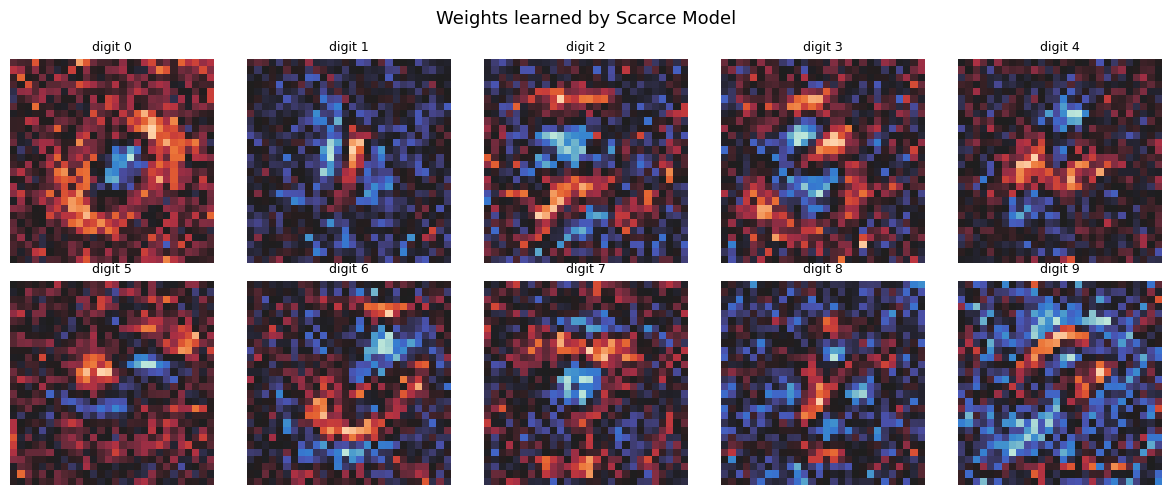

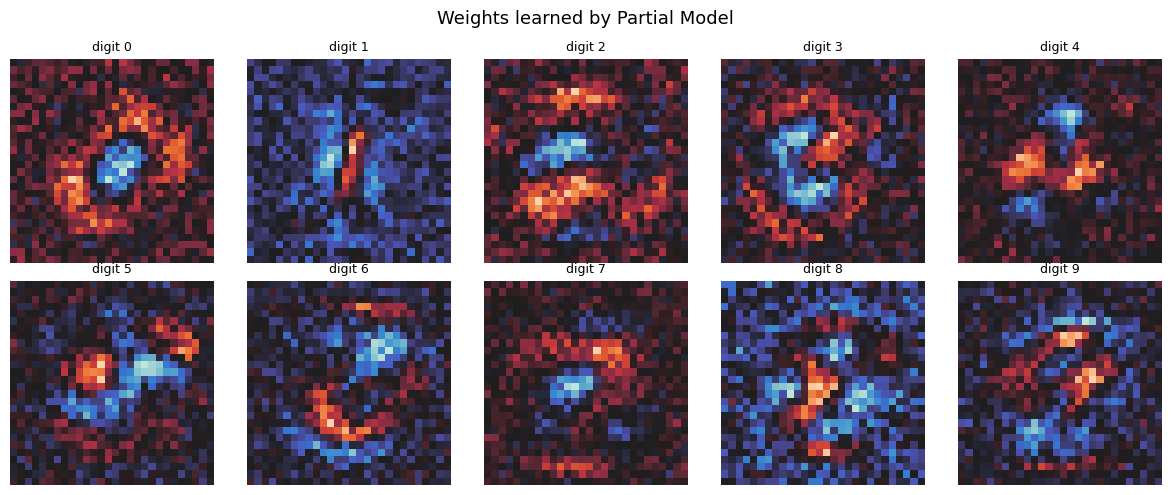

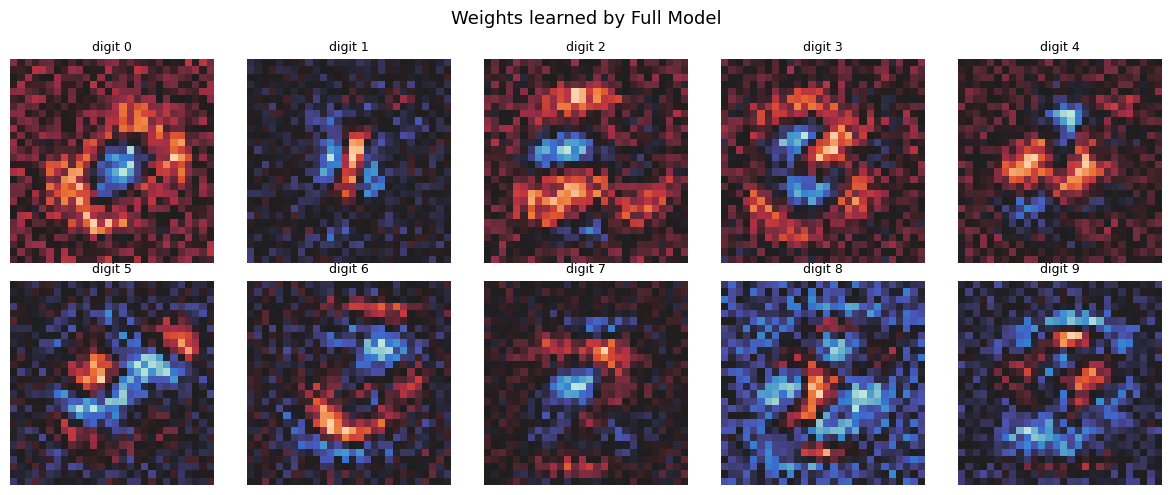

In [144]:
n_iter = 100
for name in scaled_data_regimes:
	model = LinearModel()
	X = torch.from_numpy(scaled_data_regimes[name][0]).float()
	y = torch.from_numpy(scaled_data_regimes[name][1])

	loss = train(model, X, y, n_iter)

	unregularized_models[name] = (model, loss)

	weights = model.linear.weight.detach().numpy()

	plot_weights(weights, f"Weights learned by {name} Model")


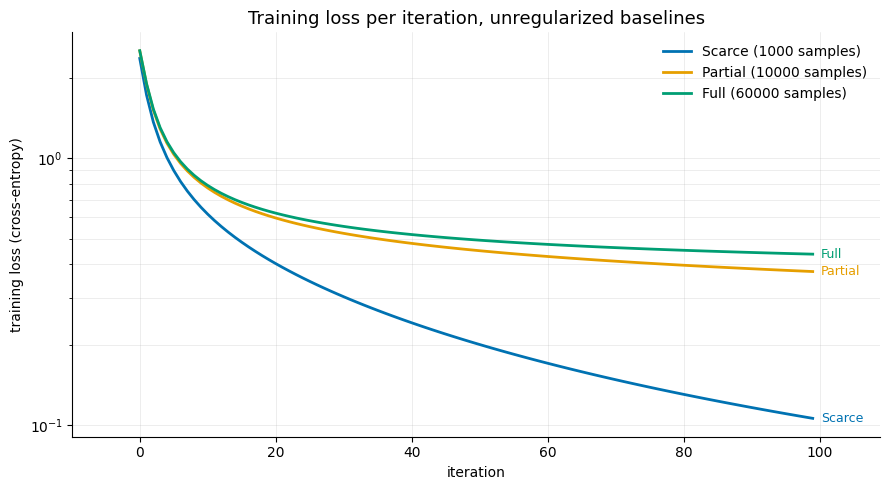

In [63]:
# plot of training loss per iteration for the three unregularized baselines.

regime_colors = {"Scarce": "#0072B2", "Partial": "#E69F00", "Full": "#009E73"}

fig, ax = plt.subplots(figsize=(9, 5))

for name, (model, loss_history) in unregularized_models.items():
	n_samples = len(data_regimes[name][1])
	ax.plot(
		loss_history,
		color=regime_colors[name],
		linewidth=2,
		label=f"{name} ({n_samples} samples)",
	)
	ax.annotate(
		name,
		xy=(len(loss_history) - 1, loss_history[-1]),
		xytext=(6, 0),
		textcoords="offset points",
		color=regime_colors[name],
		fontsize=9,
		va="center",
	)

# log scale on the y axis
ax.set_yscale("log")
ax.set_xlabel("iteration")
ax.set_ylabel("training loss (cross-entropy)")
ax.set_title("Training loss per iteration, unregularized baselines", fontsize=13)
ax.grid(True, which="both", linewidth=0.4, alpha=0.4)
ax.spines[["top", "right"]].set_visible(False)
ax.margins(x=0.10)
ax.legend(frameon=False)

plt.tight_layout()
plt.show()

> **Question 2.3**
>
> Inspect the weight images for each baseline model. How do you explain the
> weight values in the heatmap, and what patterns do they show?
>
> Compare between the model, how are they different?

**Answer:** Red pixels represent positive weights (increase log-odds for a specific class), while blue pixels represent negative weights (decrease log-odds for a specific class). Therefore we expect to see the silhouette of the target digit clearly outlined in red, rewarding the presence of pixels in those locations. The blue areas represent empty background and strokes from competing digits, allowing the model to differentiate shapes that belong to other classes.

The Scarce model displays a highly noisy background with weights scattered randomly outside the digit's core format. This is an indication that the model may be overfitting the limited data, learning to associate random noise strokes with specific classes. On the other hand, the Partial and Full models display significantly cleaner silhouettes and backgrounds, demonstrating that with sufficient data the model can successfully learn to ignore the random corruption. The visual difference between the Partial and Full plots is minimal, suggesting that 10k samples of Partial data regime are already sufficient for the model to ignore this specific random noise.

---

## Part 3. Regularization

**(2.0 points)**

We now introduce regularization and sweep over $\lambda$ values for both L1 and L2 penalties.

Your **only decision criterion** in this part is cross-validation accuracy computed on the corrupted training data, exactly what you would have in a real scenario without access to a clean or differently corrupted test set.

For each configuration (data regime x reg type x $\lambda$), use K-fold cross-validation to estimate validation accuracy (report mean **and** standard deviation across folds).
Then, for each regularizer, **select the best $\lambda$** by CV and train a final model on the full training set of that regime.

Also train and store one model for **every** $\lambda$ of the grid on the Full-data regime: they will not be used for selection, only for the diagnostic plots of Part 4.

> **Decision task** Report, per regularizer and data regimes, which $\lambda$ you selected and why.
Inspect the weight images of your chosen models and describe what you observe.

In [ ]:
from sklearn.model_selection import StratifiedKFold

lambda_grid = np.concatenate([[0.0], np.logspace(-4, 0.5, 9)])
n_folds = 5
penalties = ("L2", "L1")


def cross_validate(
	X_raw: NDArray[Any],
	y_raw: NDArray[Any],
	l1: float = 0.0,
	l2: float = 0.0
) -> list[float]:
	"""
	K-fold validation accuracy, starting from the raw images.

	A new StandardScaler is fitted on the training folds only and then applied to
	the held-out fold, so no validation statistic leaks into the preprocessing.
	"""
	X_flat = X_raw.reshape(len(X_raw), -1).astype(np.float32)
	splitter = StratifiedKFold(n_splits=n_folds, shuffle=True, random_state=seed)

	fold_accuracies = []

	for fold, (train_idx, val_idx) in enumerate(splitter.split(X_flat, y_raw)):
		scaler = StandardScaler()
		X_train = scaler.fit_transform(X_flat[train_idx])
		X_val = scaler.transform(X_flat[val_idx])

		torch.manual_seed(seed + fold)
		model = LinearModel()

		train(
			model,
			torch.from_numpy(X_train).float(),
			torch.from_numpy(y_raw[train_idx]),
			n_iter, l1=l1, l2=l2,
		)

		with torch.no_grad():
			logits = model(torch.from_numpy(X_val).float())

		fold_accuracies.append(accuracy(logits, torch.from_numpy(y_raw[val_idx])))

	return fold_accuracies


records = []

for name in data_regimes:
	X_raw, y_raw = data_regimes[name]

	for penalty in penalties:
		for lam in lambda_grid:
			kwargs = {"l2": lam} if penalty == "L2" else {"l1": lam}
			folds = cross_validate(X_raw, y_raw, **kwargs)

			records.append({
				"regime": name,
				"penalty": penalty,
				"lambda": lam,
				"cv_mean": float(np.mean(folds)),
				"cv_std": float(np.std(folds)),
				"folds": folds,
			})

cv_results = pd.DataFrame(records)
cv_results.round(4)


,regime,penalty,lambda,cv_mean,cv_std,folds
0,Scarce,L2,0.0000,0.7910,0.0312,"[0.8149999976158142, 0.7350000143051147, 0.824..."
1,Scarce,L2,0.0001,0.7910,0.0312,"[0.8149999976158142, 0.7350000143051147, 0.824..."
2,Scarce,L2,0.0004,0.7910,0.0312,"[0.8149999976158142, 0.7350000143051147, 0.824..."
3,Scarce,L2,0.0013,0.7910,0.0312,"[0.8149999976158142, 0.7350000143051147, 0.824..."
4,Scarce,L2,0.0049,0.7930,0.0306,"[0.8149999976158142, 0.7400000095367432, 0.829..."
5,Scarce,L2,0.0178,0.7960,0.0280,"[0.8199999928474426, 0.75, 0.8299999833106995,..."
6,Scarce,L2,0.0649,0.8040,0.0328,"[0.8299999833106995, 0.75, 0.8450000286102295,..."
7,Scarce,L2,0.2371,0.8040,0.0275,"[0.8299999833106995, 0.7549999952316284, 0.829..."
8,Scarce,L2,0.8660,0.7810,0.0208,"[0.7900000214576721, 0.7400000095367432, 0.785..."
9,Scarce,L2,3.1623,0.7240,0.0150,"[0.7099999785423279, 0.7049999833106995, 0.725..."


In [ ]:
# DECISION TASK: Selection rule: the one-standard-error rule (Hastie, Tibshirani & Friedman,
# "The Elements of Statistical Learning"). Among the lambdas whose
# CV accuracy lies within one standard error (sd/√K) of the maximum, the most regularized
# one is chosen. Between models that cross-validation cannot tell apart, the more
# constrained one is preferred.

def select_lambda(curve: pd.DataFrame, rule: str) -> pd.Series:
	curve = curve.sort_values("lambda").reset_index(drop=True)
	best = curve["cv_mean"].idxmax()

	if rule == "argmax":
		return curve.loc[best]

	standard_error = curve.loc[best, "cv_std"] / np.sqrt(n_folds)
	within = curve.index[curve["cv_mean"] >= curve.loc[best, "cv_mean"] - standard_error]
	return curve.loc[within.max()]


comparison, chosen = [], []

for name in data_regimes:
	for penalty in penalties:
		curve = cv_results[
			(cv_results["regime"] == name) & (cv_results["penalty"] == penalty)
		]
		a = select_lambda(curve, "argmax")
		s = select_lambda(curve, "1se")

		comparison.append({
			"regime": name, "penalty": penalty,
			"argmax_lambda": float(a["lambda"]), "argmax_cv": float(a["cv_mean"]),
			"1se_lambda": float(s["lambda"]), "1se_cv": float(s["cv_mean"]),
			"cv_std": float(a["cv_std"]),
			"cost_in_cv": float(a["cv_mean"] - s["cv_mean"]),
		})
		chosen.append({
			"regime": name, "penalty": penalty, "lambda": float(s["lambda"]),
			"cv_mean": float(s["cv_mean"]), "cv_std": float(s["cv_std"]),
		})

selection_rules = pd.DataFrame(comparison)
best_rows = pd.DataFrame(chosen).set_index(["regime", "penalty"])


def fit_final(name: str, l1: float = 0.0, l2: float = 0.0) -> nn.Module:
	X = torch.from_numpy(scaled_data_regimes[name][0]).float()
	y = torch.from_numpy(scaled_data_regimes[name][1])

	torch.manual_seed(seed)
	model = LinearModel()
	train(model, X, y, n_iter, l1=l1, l2=l2)

	return model


selected_models = {}

for (name, penalty), row in best_rows.iterrows():
	kwargs = {"l2": row["lambda"]} if penalty == "L2" else {"l1": row["lambda"]}
	selected_models[(name, penalty)] = fit_final(name, **kwargs)

full_sweep_models = {}

for penalty in penalties:
	for lam in lambda_grid:
		kwargs = {"l2": lam} if penalty == "L2" else {"l1": lam}
		full_sweep_models[(penalty, lam)] = fit_final("Full", **kwargs)

selection_rules.round(5)


,regime,penalty,argmax_lambda,argmax_cv,1se_lambda,1se_cv,cv_std,cost_in_cv
0,Scarce,L2,0.06494,0.80400,0.23714,0.80400,0.03277,0.00000
1,Scarce,L1,0.00487,0.81800,0.00487,0.81800,0.02272,0.00000
2,Partial,L2,0.01778,0.86020,0.06494,0.85670,0.00951,0.00350
3,Partial,L1,0.00133,0.86090,0.00133,0.86090,0.00970,0.00000
4,Full,L2,0.00487,0.86715,0.01778,0.86677,0.00094,0.00038
5,Full,L1,0.00037,0.86717,0.00133,0.86712,0.00105,0.00005


In [ ]:

rows = []

for name in data_regimes:
	for penalty in penalties:
		curve = cv_results[
			(cv_results["regime"] == name) & (cv_results["penalty"] == penalty)
		].sort_values("lambda").reset_index(drop=True)

		best = curve["cv_mean"].idxmax()
		neighbours = curve.loc[[i for i in (best - 1, best + 1) if 0 <= i < len(curve)]]
		gap = curve.loc[best, "cv_mean"] - neighbours["cv_mean"].max()

		rows.append({
			"regime": name,
			"penalty": penalty,
			"best_lambda": curve.loc[best, "lambda"],
			"cv_mean": curve.loc[best, "cv_mean"],
			"cv_std": curve.loc[best, "cv_std"],
			"gap_to_neighbour": gap,
			"gap > std": gap > curve.loc[best, "cv_std"],
		})

selection_table = pd.DataFrame(rows)
selection_table.round(5)


,regime,penalty,best_lambda,cv_mean,cv_std,gap_to_neighbour,gap > std
0,Scarce,L2,0.06494,0.80400,0.03277,0.00000,False
1,Scarce,L1,0.00487,0.81800,0.02272,0.01800,False
2,Partial,L2,0.01778,0.86020,0.00951,0.00050,False
3,Partial,L1,0.00133,0.86090,0.00970,0.00050,False
4,Full,L2,0.00487,0.86715,0.00094,0.00012,False
5,Full,L1,0.00037,0.86717,0.00105,0.00005,False


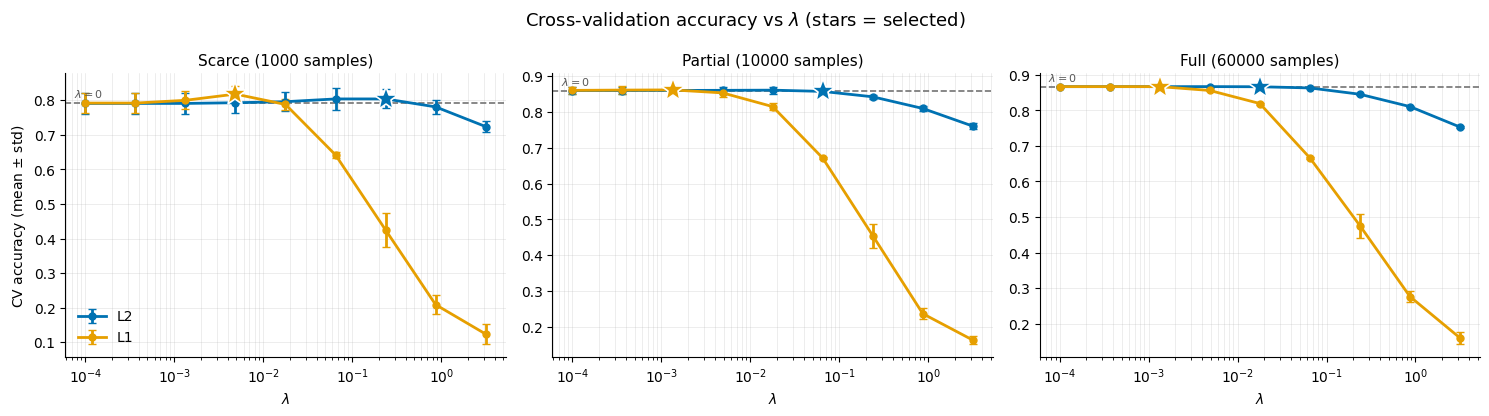

In [134]:
penalty_colors = {"L2": "#0072B2", "L1": "#E69F00"}

fig, axs = plt.subplots(1, len(data_regimes), figsize=(5 * len(data_regimes), 4.2))

for ax, name in zip(axs, data_regimes):
	sub = cv_results[cv_results["regime"] == name]

	baseline = sub[sub["lambda"] == 0.0]["cv_mean"].iloc[0]
	ax.axhline(baseline, color="0.45", linestyle="--", linewidth=1.2)
	ax.annotate(
		"$\\lambda = 0$", xy=(0.02, baseline), xycoords=("axes fraction", "data"),
		xytext=(0, 4), textcoords="offset points", color="0.35", fontsize=8,
	)

	for penalty in penalties:
		curve = sub[(sub["penalty"] == penalty) & (sub["lambda"] > 0)].sort_values("lambda")
		ax.errorbar(
			curve["lambda"], curve["cv_mean"], yerr=curve["cv_std"],
			color=penalty_colors[penalty], linewidth=2, marker="o", markersize=5,
			capsize=3, label=penalty,
		)

		chosen = best_rows.loc[(name, penalty)]
		if chosen["lambda"] > 0:
			ax.plot(
				chosen["lambda"], chosen["cv_mean"], marker="*", markersize=18,
				color=penalty_colors[penalty], markeredgecolor="white",
				markeredgewidth=1.2, linestyle="none", zorder=5,
			)

	ax.set_xscale("log")
	ax.set_xlabel("$\\lambda$")
	ax.set_title(f"{name} ({len(data_regimes[name][1])} samples)", fontsize=11)
	ax.grid(True, which="both", linewidth=0.4, alpha=0.4)
	ax.spines[["top", "right"]].set_visible(False)

axs[0].set_ylabel("CV accuracy (mean $\\pm$ std)")
axs[0].legend(frameon=False)
fig.suptitle("Cross-validation accuracy vs $\\lambda$ (stars = selected)", fontsize=13)
plt.tight_layout()
plt.show()


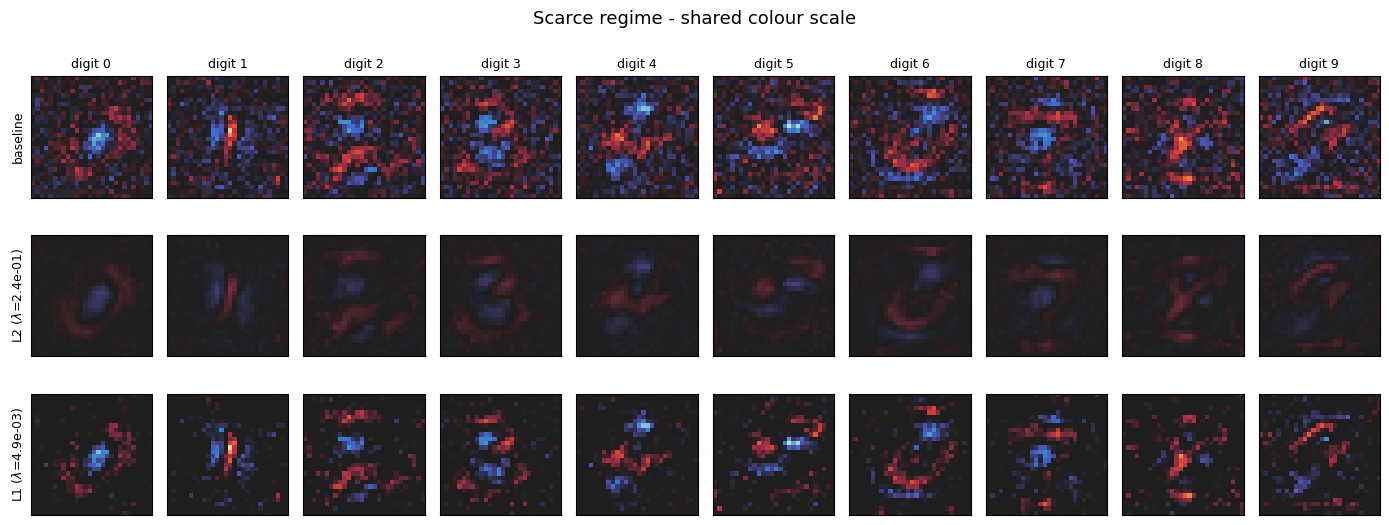

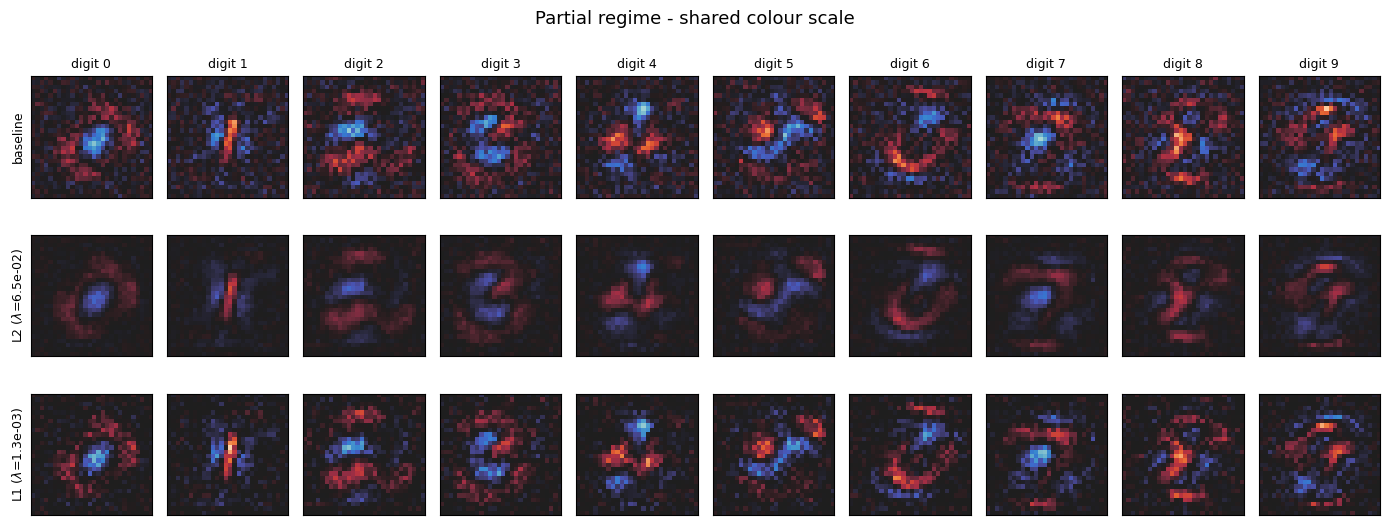

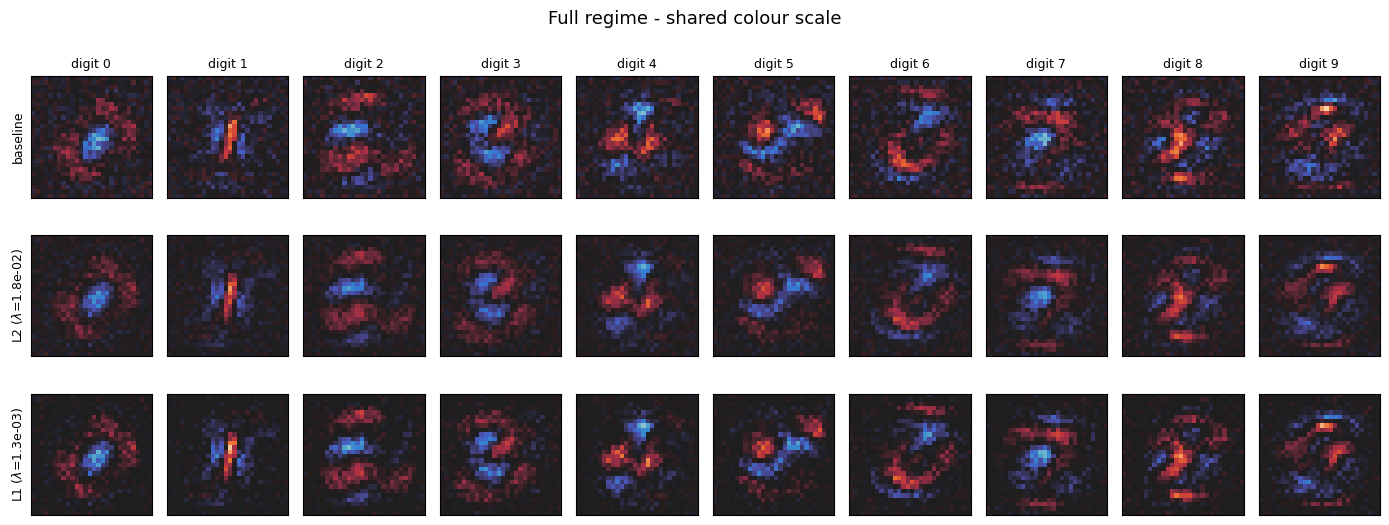

In [ ]:
def compare_weights(name: str) -> None:
	"""
	Comparison for Baseline, CV-selected L2 and CV-selected L1.

	"""
	rows = {"baseline": unregularized_models[name][0]}
	for penalty in penalties:
		lam = best_rows.loc[(name, penalty), "lambda"]
		rows[f"{penalty} ($\\lambda$={lam:.1e})"] = selected_models[(name, penalty)]

	all_weights = {
		label: model.linear.weight.detach().numpy() for label, model in rows.items()
	}
	limit = max(np.abs(w).max() for w in all_weights.values())

	fig, axs = plt.subplots(len(rows), 10, figsize=(14, 1.6 * len(rows) + 0.8))

	for i, (label, weights) in enumerate(all_weights.items()):
		for digit in range(10):
			ax = axs[i, digit]
			ax.imshow(
				weights[digit].reshape(28, 28), cmap="icefire",
				vmin=-limit, vmax=limit,
			)
			ax.set_xticks([]); ax.set_yticks([])
			if i == 0:
				ax.set_title(f"digit {digit}", fontsize=9)

		axs[i, 0].set_ylabel(label, fontsize=9)

	fig.suptitle(f"{name} regime - shared colour scale", fontsize=13)
	plt.tight_layout()
	plt.show()


for name in data_regimes:
	compare_weights(name)


> **Question 3**
>
> (a) As $\lambda$ increases for L2 regularization, how does CV accuracy change on each data regime?
> Are there clear optima, or does accuracy plateau? Is the difference between the best $\lambda$ and its neighbours larger than the fold-to-fold standard deviation?
>
> (b) Compare the weight images of the CV-selected L2 model, the CV-selected L1 model, and the unregularized baseline. What differences do you observe in terms of structure and sparsity?
>
> (c) Connect the weight images to the corruption structure identified in Part 1. Does the CV-selected model appear to have suppressed the corruption pattern, amplified it, or is it ambiguous from weights alone?
>
> (d) **Predict**, based on what you see in the weights and CV curves, which of your three CV-selected models (none / L2 / L1) you expect will perform best on clean images, and which on images with impulse noise. Justify your prediction before seeing any test results.

**Answer:**

**(a)** For L2 the CV accuracy rises slightly before falling in all three regimes. Scarce rises by +0.0130 before peaking at $\lambda = 0.0649$, Partial by +0.0012 (peak at $\lambda = 0.0178$) and Full by +0.0001 (peak at $\lambda = 0.0049$). After the peak all three curves decrease steeply: at the largest grid value the Full regime has dropped from 0.8670 to 0.7533.

These rises, however, are not conclusive. The fold-to-fold standard deviations at the peaks are 0.0328 (Scarce), 0.0095 (Partial) and 0.0009 (Full), each larger than the corresponding rise, and the difference between the best $\lambda$ and its best neighbour is never larger than the fold-to-fold standard deviation, in any regime and for either penalty. All six curves are therefore better described as plateaus than as clear optima. Taken at face value, regularization helps most in Scarce and almost not at all in Full, as we expected, but the data cannot confirm it. What clearly differs between the regimes is the noise itself, more than 30 times larger in Scarce than in Full: the regime that would benefit most from regularization is also the one where that benefit is hardest to detect.

This is what motivates the selection rule we adopted. Since the maxima are not statistically distinguishable from their neighbours, selecting by `argmax` is essentially arbitrary. We instead use the one-standard-error rule (Hastie, Tibshirani & Friedman, "The Elements of Statistical Learning"). Among the lambdas whose CV accuracy lies within one standard error (sd/√K) of the maximum, the most regularized one is chosen. Between models that cross-validation cannot tell apart, the more constrained one is preferred.

**(b)** 
*Structure.* The contrast is clearest in Scarce, where the selected $\lambda$ are largest. In the baseline the digit silhouette is present but buried: a recognizable red/blue core sits inside a field of speckled background weights that carry no digit structure. Both penalties remove that field, but they remove it differently. Under L2 ($\lambda = 0.24$) the whole image dims: the background becomes smooth and continuous, and the silhouette itself is attenuated along with it, so the surviving structure is softer and lower in contrast than in the baseline. Under L1 ($\lambda = 0.0049$) the surviving weights keep roughly the brightness they had in the baseline, while regions of background drop to black. The silhouette therefore stays sharp and the background becomes patchy rather than smooth.

*Sparsity.* This is the mechanical difference between the two penalties, and it is visible in the images. In the L1 row the weights look bimodal: large parts of the background drop to the black that marks zero, while the surviving pixels keep roughly their baseline brightness. In the L2 row there is no such split: the whole map dims uniformly, background and silhouette shrinking together. L1 drives a subset of weights to zero and leaves the rest almost untouched, while L2 shrinks every weight in proportion. Since the colour scale cannot separate an exactly-zero weight from a very small one, the figure shows the pattern of sparsity, not how many weights are actually zero.

In the Full regime the same pattern holds but is much weaker, because the selected $\lambda$ are small (0.0178 and 0.0013): with 60000 samples cross-validation sees little reason to regularize, and the three rows nearly coincide.

**(c)** In Part 1 we established that the corruption consists of white stroke-like lines, drawn independently in each sample, uniformly distributed in position and uncorrelated with the class. For the weights, since the corruption occupies every position with roughly equal probability, there is no particular pattern in a 28×28 weight map that could be identified as "the corruption".

What we do observe is that the regularized models have much weaker background weights than the baseline. That is consistent with suppression of spurious corruption-driven weights, but it is also what any penalty does to weights that carry no signal, whatever their origin: fitted corruption, sampling noise from a small training set, or leftover random initialization. So, our answer is **ambiguous from weights alone**. The weight images show that regularization shrank the uninformative background, but they cannot tell us where that background came from.

**(d)** Our prediction, based only on the weights and the CV curves:

- On **`test_clean`** we expect the **unregularized baseline** to be best. The clean split contains no corruption at all, so there is no spurious signal for the penalty to remove; every weight that regularization shrinks or zeroes can only remove genuine information about the digit. We therefore expect accuracy on clean to decrease monotonically with $\lambda$.
- On **`test_impulse`** we expect **L1** to be best. Impulse noise saturates random pixels across the whole image, including the periphery where no digit ever appears. The selected L1 model reads fewer pixels than the others, as the black background regions of its weight images in (b) show, so a smaller fraction of the corrupted pixels can reach its decision. L2 shrinks every weight but keeps reading every pixel, which should attenuate the noise without excluding it.

**Decision task.** Using the one-standard-error rule we selected $\lambda = 0.2371$ (L2) and $0.0049$ (L1) for Scarce, $0.0649$ and $0.0013$ for Partial, and $0.0178$ and $0.0013$ for Full. Compared with the argmax, the rule changed the L2 choice in all three regimes and the L1 choice in Full, at a cost of at most 0.0035 in CV accuracy. The weight images of these models are described in (b).


---

## Part 4. Test

**(2.0 points)**

Until now, all decisions, dataset size analysis, regularization selection, were made using only the corrupted training data and cross-validation.
**Now we use the test sets** to evaluate the models you selected.

1. Evaluate all the chosen models (baseline, CV-selected L2 and L1, for each data regime) on the three test splits.
2. Using the Full-data models stored for every $\lambda$, plot the **trade-off curves**: accuracy on `test_corrupted` versus accuracy on `test_clean`, and versus `test_impulse`, one curve per regularizer, marking the CV-selected models.
3. Plot the **sparsity** (fraction of weights with $|w| < 10^{-3}$) of the L1 and L2 models against $\lambda$.
4. Compute the **per-class accuracy** on each test split for the CV-selected models and identify which digits suffer the most from each corruption.

In [ ]:
test_labels = np.load(f"{DATA_DIR}/test/test_labels.npy")

test_splits = {
	"corrupted": np.load(f"{DATA_DIR}/test/test_images.npy"),
	"clean":     np.load(f"{DATA_DIR}/test/clean_images.npy"),
	"impulse":   np.load(f"{DATA_DIR}/test/impulse_images.npy"),
}

y_test = torch.from_numpy(test_labels)


def evaluate(model: nn.Module, name: str) -> dict[str, float]:
	"""
	Accuracy on the three test splits.

	"""
	scaler = scaled_data_regimes[name][2]
	scores = {}

	for split, X_split in test_splits.items():
		X_flat = X_split.reshape(len(X_split), -1).astype(np.float32)
		X_scaled = torch.from_numpy(scaler.transform(X_flat)).float()

		with torch.no_grad():
			scores[split] = accuracy(model(X_scaled), y_test)

	return scores


rows = []

for name in data_regimes:
	rows.append({
		"regime": name, "model": "baseline", "lambda": 0.0,
		**evaluate(unregularized_models[name][0], name),
	})

	for penalty in penalties:
		rows.append({
			"regime": name, "model": f"CV {penalty}",
			"lambda": best_rows.loc[(name, penalty), "lambda"],
			**evaluate(selected_models[(name, penalty)], name),
		})

test_results = pd.DataFrame(rows)
test_results["gap_clean"] = test_results["corrupted"] - test_results["clean"]
test_results["gap_impulse"] = test_results["corrupted"] - test_results["impulse"]
test_results.round(4)


,regime,model,lambda,corrupted,clean,impulse,gap_clean,gap_impulse
0,Scarce,baseline,0.0000,0.8265,0.8587,0.7883,-0.0322,0.0382
1,Scarce,CV L2,0.2371,0.8267,0.8425,0.8272,-0.0158,-0.0005
2,Scarce,CV L1,0.0049,0.8405,0.8568,0.8328,-0.0163,0.0077
3,Partial,baseline,0.0000,0.8656,0.8870,0.8484,-0.0214,0.0172
4,Partial,CV L2,0.0649,0.8672,0.8809,0.8674,-0.0137,-0.0002
5,Partial,CV L1,0.0013,0.8714,0.8878,0.8633,-0.0164,0.0081
6,Full,baseline,0.0000,0.8767,0.8894,0.8609,-0.0127,0.0158
7,Full,CV L2,0.0178,0.8762,0.8879,0.8659,-0.0117,0.0103
8,Full,CV L1,0.0013,0.8761,0.8883,0.8722,-0.0122,0.0039


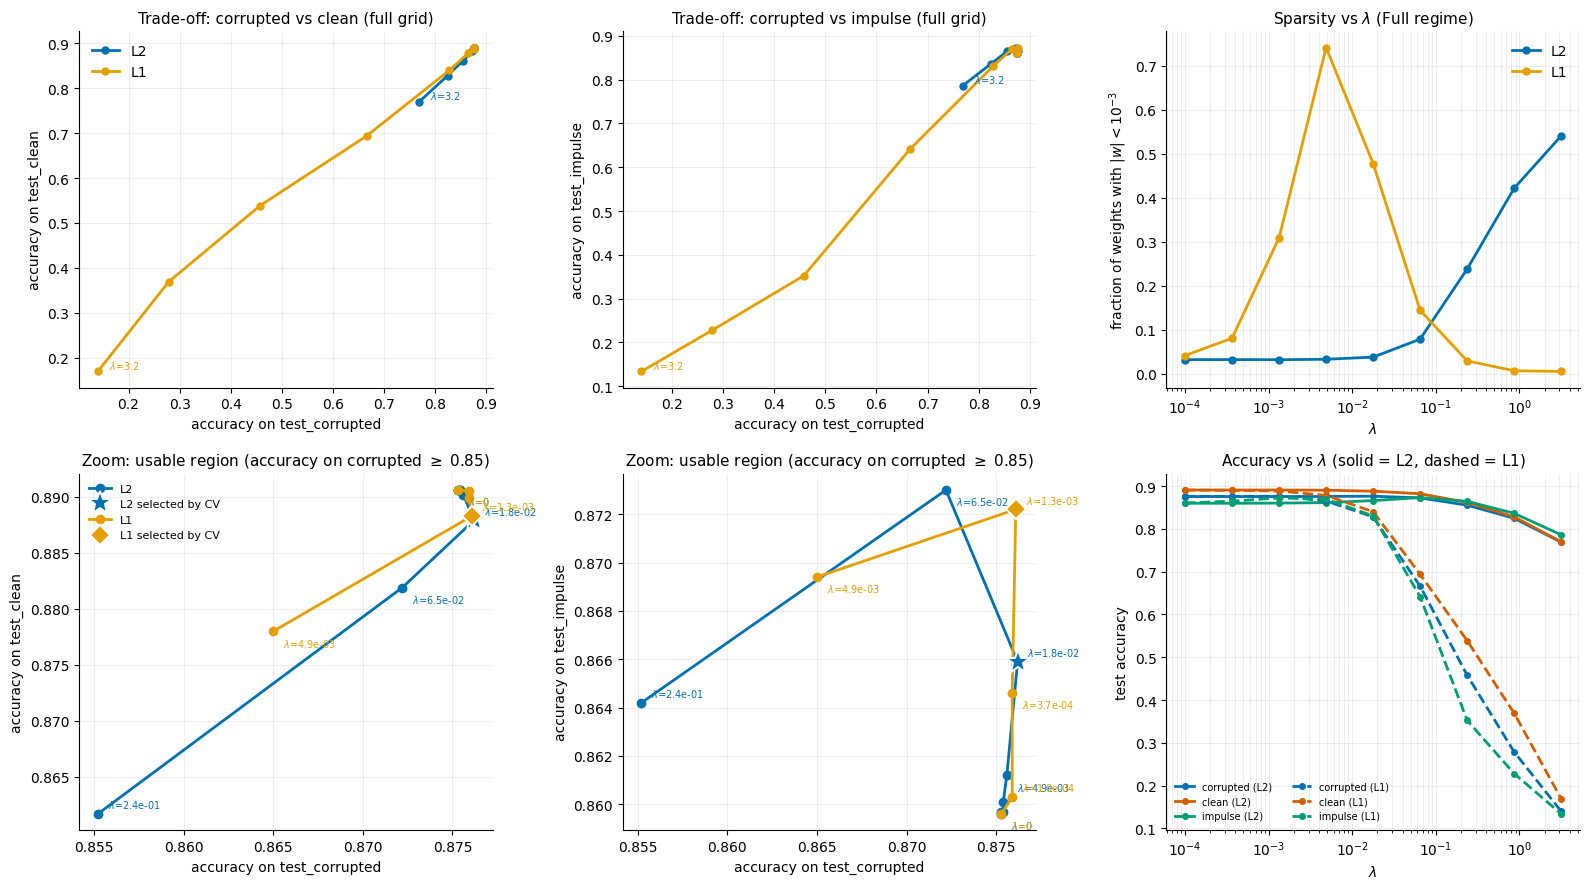

In [ ]:

rows = []

for (penalty, lam), model in full_sweep_models.items():
	weights = model.linear.weight.detach().numpy()
	rows.append({
		"penalty": penalty, "lambda": lam,
		"sparsity": float((np.abs(weights) < 1e-3).mean()),
		**evaluate(model, "Full"),
	})

sweep_results = pd.DataFrame(rows).sort_values(["penalty", "lambda"])

split_colors = {"corrupted": "#0072B2", "clean": "#D55E00", "impulse": "#009E73"}
usable = sweep_results[sweep_results["corrupted"] >= 0.85]

fig, axs = plt.subplots(2, 3, figsize=(16, 9))

# ---- top row: full grid ----
for ax, other in zip(axs[0, :2], ["clean", "impulse"]):
	for penalty in penalties:
		curve = sweep_results[sweep_results["penalty"] == penalty]
		ax.plot(curve["corrupted"], curve[other], color=penalty_colors[penalty],
			linewidth=2, marker="o", markersize=5, label=penalty)

		end = curve.iloc[-1]
		ax.annotate(f"$\\lambda$={end['lambda']:.2g}",
			xy=(end["corrupted"], end[other]), xytext=(8, 2),
			textcoords="offset points", fontsize=7, color=penalty_colors[penalty])

	ax.set_xlabel("accuracy on test_corrupted")
	ax.set_ylabel(f"accuracy on test_{other}")
	ax.set_title(f"Trade-off: corrupted vs {other} (full grid)", fontsize=11)
	ax.grid(True, linewidth=0.4, alpha=0.4)
	ax.spines[["top", "right"]].set_visible(False)

axs[0, 0].legend(frameon=False)

for penalty in penalties:
	curve = sweep_results[(sweep_results["penalty"] == penalty) & (sweep_results["lambda"] > 0)]
	axs[0, 2].plot(curve["lambda"], curve["sparsity"], color=penalty_colors[penalty],
		linewidth=2, marker="o", markersize=5, label=penalty)

axs[0, 2].set_xscale("log")
axs[0, 2].set_xlabel("$\\lambda$")
axs[0, 2].set_ylabel("fraction of weights with $|w| < 10^{-3}$")
axs[0, 2].set_title("Sparsity vs $\\lambda$ (Full regime)", fontsize=11)
axs[0, 2].grid(True, which="both", linewidth=0.4, alpha=0.4)
axs[0, 2].spines[["top", "right"]].set_visible(False)
axs[0, 2].legend(frameon=False)

# ---- bottom row: zoom on the usable region ----
for ax, other in zip(axs[1, :2], ["clean", "impulse"]):
	for penalty in penalties:
		curve = usable[usable["penalty"] == penalty]
		ax.plot(curve["corrupted"], curve[other], color=penalty_colors[penalty],
			linewidth=2, marker="o", markersize=6, label=penalty)

		span_x = usable["corrupted"].max() - usable["corrupted"].min()
		span_y = usable[other].max() - usable[other].min()
		last = None
		for k, (_, r) in enumerate(curve.iterrows()):
			far = last is None or (abs(r["corrupted"] - last[0]) > 0.05 * span_x
				or abs(r[other] - last[1]) > 0.05 * span_y)
			if far:
				txt = "0" if r["lambda"] == 0 else f"{r['lambda']:.1e}"
				ax.annotate(f"$\\lambda$={txt}", xy=(r["corrupted"], r[other]),
					xytext=(7, 4 if k % 2 else -11), textcoords="offset points",
					fontsize=7, color=penalty_colors[penalty])
				last = (r["corrupted"], r[other])

		sel = best_rows.loc[("Full", penalty), "lambda"]
		point = curve[np.isclose(curve["lambda"], sel)]
		marker = "*" if penalty == "L2" else "D"
		ax.plot(point["corrupted"], point[other], marker=marker,
			markersize=18 if penalty == "L2" else 10,
			color=penalty_colors[penalty], markeredgecolor="white",
			markeredgewidth=1.4, linestyle="none", zorder=5,
			label=f"{penalty} selected by CV")

	ax.set_xlabel("accuracy on test_corrupted")
	ax.set_ylabel(f"accuracy on test_{other}")
	ax.set_title(f"Zoom: usable region (accuracy on corrupted $\\geq$ 0.85)", fontsize=11)
	ax.grid(True, linewidth=0.4, alpha=0.4)
	ax.spines[["top", "right"]].set_visible(False)

axs[1, 0].legend(frameon=False, fontsize=8)

# lambda as an explicit axis: colour = test split and line style = penalty
for penalty, style in (("L2", "-"), ("L1", "--")):
	curve = sweep_results[(sweep_results["penalty"] == penalty) & (sweep_results["lambda"] > 0)]
	for split, colour in split_colors.items():
		axs[1, 2].plot(curve["lambda"], curve[split], color=colour, linestyle=style,
			linewidth=2, marker="o", markersize=4,
			label=f"{split} ({penalty})")

axs[1, 2].set_xscale("log")
axs[1, 2].set_xlabel("$\\lambda$")
axs[1, 2].set_ylabel("test accuracy")
axs[1, 2].set_title("Accuracy vs $\\lambda$ (solid = L2, dashed = L1)", fontsize=11)
axs[1, 2].grid(True, which="both", linewidth=0.4, alpha=0.4)
axs[1, 2].spines[["top", "right"]].set_visible(False)
axs[1, 2].legend(frameon=False, fontsize=7, ncol=2)

plt.tight_layout()
plt.show()


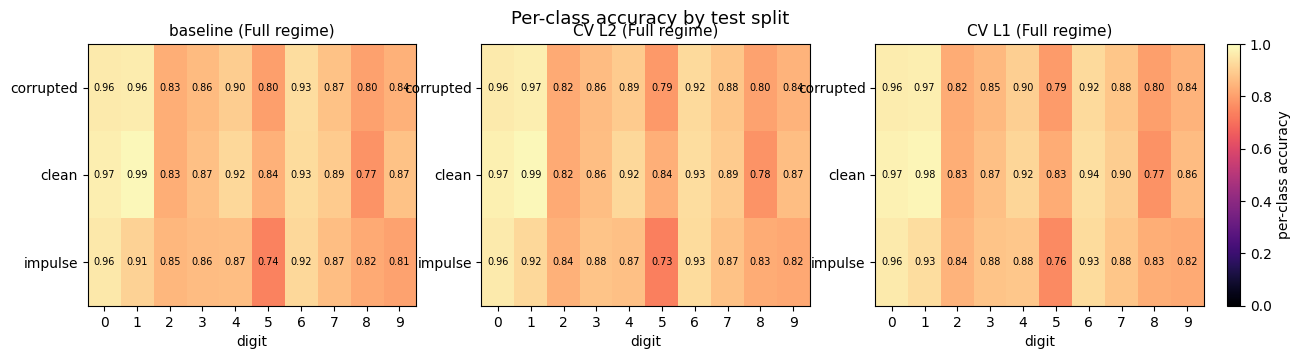


baseline -- worst three digits per split
  corrupted 5: 0.799  8: 0.804  2: 0.830
  clean     8: 0.774  2: 0.828  5: 0.839
  impulse   5: 0.739  9: 0.806  8: 0.820

CV L2 -- worst three digits per split
  corrupted 5: 0.788  8: 0.805  2: 0.824
  clean     8: 0.776  2: 0.824  5: 0.835
  impulse   5: 0.734  9: 0.819  8: 0.826

CV L1 -- worst three digits per split
  corrupted 5: 0.791  8: 0.799  2: 0.825
  clean     8: 0.773  5: 0.827  2: 0.830
  impulse   5: 0.756  9: 0.823  8: 0.830


In [ ]:
# Item 4: per-class accuracy
def per_class_accuracy(model: nn.Module, name: str) -> dict[str, NDArray[Any]]:
	scaler = scaled_data_regimes[name][2]
	out = {}

	for split, X_split in test_splits.items():
		X_flat = X_split.reshape(len(X_split), -1).astype(np.float32)
		with torch.no_grad():
			pred = model(torch.from_numpy(scaler.transform(X_flat)).float()).argmax(dim=-1).numpy()

		out[split] = np.array([
			(pred[test_labels == digit] == digit).mean() for digit in range(10)
		])

	return out


inspected = {"baseline": unregularized_models["Full"][0]}
for penalty in penalties:
	inspected[f"CV {penalty}"] = selected_models[("Full", penalty)]

fig, axs = plt.subplots(1, len(inspected), figsize=(5 * len(inspected), 3.4))

per_class_tables = {}

for ax, (label, model) in zip(axs, inspected.items()):
	table = pd.DataFrame(per_class_accuracy(model, "Full"), index=range(10)).T
	per_class_tables[label] = table

	im = ax.imshow(table.values, cmap="magma", vmin=0, vmax=1, aspect="auto")
	ax.set_xticks(range(10)); ax.set_xlabel("digit")
	ax.set_yticks(range(len(table))); ax.set_yticklabels(table.index)
	ax.set_title(f"{label} (Full regime)", fontsize=11)

	for i in range(table.shape[0]):
		for j in range(10):
			v = table.values[i, j]
			ax.text(j, i, f"{v:.2f}", ha="center", va="center", fontsize=7,
				color="white" if v < 0.6 else "black")

fig.colorbar(im, ax=axs, fraction=0.02, pad=0.02, label="per-class accuracy")
fig.suptitle("Per-class accuracy by test split", fontsize=13)
plt.show()

for label, table in per_class_tables.items():
	print(f"\n{label} -- worst three digits per split")
	for split in table.index:
		worst = table.loc[split].nsmallest(3)
		print(f"  {split:<10}" + "  ".join(f"{d}: {v:.3f}" for d, v in worst.items()))


In [ ]:
# Summary table rows
full_sweep = sweep_results.copy()
full_cv = cv_results[cv_results["regime"] == "Full"].set_index(["penalty", "lambda"])

rows = []

base = test_results[(test_results["regime"] == "Full") & (test_results["model"] == "baseline")].iloc[0]
rows.append({"model": "No regularization (baseline)", "lambda": 0.0,
	"cv_mean": full_cv.loc[("L2", 0.0), "cv_mean"], "cv_std": full_cv.loc[("L2", 0.0), "cv_std"],
	"corrupted": base["corrupted"], "clean": base["clean"], "impulse": base["impulse"]})

for penalty in penalties:
	r = test_results[(test_results["regime"] == "Full") & (test_results["model"] == f"CV {penalty}")].iloc[0]
	lam = r["lambda"]
	rows.append({"model": f"Best CV, {penalty}", "lambda": lam,
		"cv_mean": full_cv.loc[(penalty, lam), "cv_mean"], "cv_std": full_cv.loc[(penalty, lam), "cv_std"],
		"corrupted": r["corrupted"], "clean": r["clean"], "impulse": r["impulse"]})

for metric, other in [("clean", "clean"), ("impulse", "impulse")]:
	for penalty in penalties:
		curve = full_sweep[full_sweep["penalty"] == penalty].copy()
		curve["gap"] = (curve["corrupted"] - curve[other]).abs()
		best = curve.loc[curve["gap"].idxmin()]
		rows.append({"model": f"Smallest {metric} gap, {penalty}", "lambda": best["lambda"],
			"cv_mean": full_cv.loc[(penalty, best["lambda"]), "cv_mean"],
			"cv_std": full_cv.loc[(penalty, best["lambda"]), "cv_std"],
			"corrupted": best["corrupted"], "clean": best["clean"], "impulse": best["impulse"]})

summary_table = pd.DataFrame(rows)
summary_table["gap_clean"] = summary_table["corrupted"] - summary_table["clean"]
summary_table["gap_impulse"] = summary_table["corrupted"] - summary_table["impulse"]
summary_table.round(4)


,model,lambda,cv_mean,cv_std,corrupted,clean,impulse,gap_clean,gap_impulse
0,No regularization (baseline),0.0000,0.8670,0.0011,0.8767,0.8894,0.8609,-0.0127,0.0158
1,"Best CV, L2",0.0178,0.8668,0.0011,0.8762,0.8879,0.8659,-0.0117,0.0103
2,"Best CV, L1",0.0013,0.8671,0.0009,0.8761,0.8883,0.8722,-0.0122,0.0039
3,"Smallest clean gap, L2",3.1623,0.7533,0.0020,0.7688,0.7696,0.7859,-0.0008,-0.0171
4,"Smallest clean gap, L1",0.0178,0.8195,0.0028,0.8279,0.8398,0.8301,-0.0119,-0.0022
5,"Smallest impulse gap, L2",0.0649,0.8634,0.0011,0.8722,0.8819,0.8730,-0.0097,-0.0008
6,"Smallest impulse gap, L1",0.0178,0.8195,0.0028,0.8279,0.8398,0.8301,-0.0119,-0.0022


> **Question 4**
>
> (a) Describe the shape of the trade-off curve (corrupted-test vs. clean-test). Is there a region where increasing regularization simultaneously improves both accuracies? Is there a region of genuine trade-off?
>
> (b) The CV-selected models are marked on the plot. Where do they fall relative to the trade-off frontier? What does this tell you about using cross-validation as a model selection criterion when training and deployment distributions differ?
>
> (c) Revisit your prediction from Question 3(d). Was it correct? If not, what did the weight images fail to reveal that the test results exposed?
>
> (d) Connect the sparsity plot to the out-of-distribution results. Why might L1 regularization behave differently from L2 when evaluated on clean images and on impulse noise?
>
> (e) Compare `test_clean` and `test_impulse`. Did training on one corruption make the model robust to a different one? Which data regime and which regularizer transferred best, and why?
>
> (f) Use the per-class accuracies to check your answer to Question 1.1(c). Which digits suffer the most under each corruption?
>
> (g) In a real deployment scenario, neither the clean nor the impulse test set would be available during model selection. Given only corrupted validation data, what practical strategies could a practitioner use to make a better model selection decision than simply maximizing CV accuracy?

**Answer:**

**(a)** On corrupted vs. clean there is no region where both improve: clean accuracy never rises with $\lambda$. For small $\lambda$ the curve barely moves — corrupted changes by less than the noise while clean drifts down slightly (0.8894 for the baseline, 0.8879 for the selected L2) — and beyond $\lambda \approx 0.02$ both fall together. The only trade-off is a weak one at small $\lambda$, where a little clean accuracy is lost for no measurable gain on corrupted, and since these differences are within the noise it is not conclusive. The impulse panel behaves differently: there, regularization first raises impulse accuracy at no measurable cost on corrupted, and only past $\lambda \approx 0.02$ does a genuine trade-off appear, with impulse still rising up to $\lambda = 0.0649$ while corrupted starts to fall.

**(b)** Both CV-selected models sit at the top-right end of the curves, next to the unregularized model, where corrupted accuracy is highest and flat — the plateau found in 3(a). Cross-validation could only choose within that plateau, because corrupted is the only distribution it sees, and its choice is not the best on the other two axes. On clean, no regularized model beats the unregularized one, although the differences are within the noise. On impulse, L2 keeps improving past its selected point and reaches 0.8730 at $\lambda = 0.0649$, against 0.8659 at the selected $\lambda = 0.0178$, while the selected L1 (0.8722) is already near that level. When deployment differs from training, cross-validation optimizes the wrong distribution, and nothing in its curve tells which $\lambda$ will transfer best.

**(c)** The impulse prediction is confirmed: L1 is clearly the best of the three (0.8722, against 0.8659 for L2 and 0.8609 for the baseline). The clean prediction is consistent with the data but not conclusive: the baseline is numerically the best, but the three models lie within 0.0015 of each other, which is comparable to the fold-to-fold variation measured in Part 3. This asymmetry is what the weight images could not reveal: the three Full models look almost identical, yet regularization brings a clear gain on impulse and nothing measurable on clean.

**(d)** The two sparsity curves behave very differently. L1 makes the weights sparse quickly — 31% are near zero at the selected $\lambda = 0.0013$ and 74% at $\lambda = 0.0049$ — while L2 keeps almost all of them above the threshold (3.7% at its selected $\lambda = 0.0178$) and only becomes sparse once the model is heavily over-regularized, reaching 54% at the largest $\lambda$.

This matches the out-of-distribution results. L1 removes pixels, L2 only damps them. Impulse noise lands at random positions over the whole frame, including the periphery where no digit appears: a pixel with zero weight simply ignores it, while a small non-zero weight still lets some of it through. That is consistent with the selected L1 beating the selected L2 on impulse (0.8722 against 0.8659). On clean there is no noise to exclude, so zeroing pixels has nothing to gain, and the two are indistinguishable.

At large $\lambda$ the L1 curve falls back to almost no sparsity (0.5% at $\lambda = 3.16$) while its accuracy drops close to chance (0.14 on corrupted). That is not what strong regularization looks like — an L1 penalty that large should push nearly all weights to zero — so these points indicate that the optimization did not converge: at $\lambda = 3.16$ the subgradient step $\eta\lambda = 0.316$ is far larger than the $10^{-3}$ threshold, and the weights keep jumping around zero instead of settling. They should not be read as part of the regularization path.

**(e)** Only partly. Every unregularized baseline loses accuracy when moving from the corruption it was trained on to impulse noise, and the loss grows as data shrinks: 1.6 points in Full, 1.7 in Partial and 3.8 in Scarce. Robustness to strokes therefore does not transfer to impulse by itself. Regularization is what closes the gap: with the selected L2 it practically disappears in Scarce and Partial ($-0.0005$ and $-0.0002$), and in Full the selected L1 reduces it to 0.0039. The best impulse accuracy overall is Full with L1 (0.8722), the regime with the most data combined with the sparsest model, for the reason discussed in (d). Since the three test splits contain the same 10000 images, these differences come from the corruption alone, not from sampling; the ranking between L1 and L2 within Scarce and Partial is less certain, as their gaps differ by less than one point.

**(f)** Our prediction in 1.1(c), that digits with straight strokes such as 1, 7 and 4 would suffer most, does not hold. For all three Full models the worst digits are 5, 8 and 2 on corrupted and clean, and 5, 9 and 8 on impulse; 1, 7 and 4 are not among them, and digit 1 is actually one of the easiest classes (0.96–0.97 on corrupted, 0.98–0.99 on clean). Digit 5 is the worst on corrupted and impulse, and digit 8 on clean. A plausible explanation is that the hardest digits are those whose shapes are close to other digits, such as 5, 8, 3 and 2, which a single linear template per class separates poorly; confirming it would require a confusion matrix, which we did not compute.

**(g)** First, do not trust the argmax when it lies inside the noise: in all six cases of Part 3 the best $\lambda$ beat its neighbour by less than the fold-to-fold standard deviation. The one-standard-error rule we used picks the most regularized model among the statistically equivalent ones; it changed four of the six choices at a cost of at most 0.0035 in CV accuracy, and on Full the L2 model it selected does better on impulse than the argmax one (0.8659 against 0.8612). Second, prefer the simpler model among equivalent ones, since it has fewer ways to depend on features specific to the training distribution. Third, use quantities that need no test data as tie-breakers, such as the weight norm or the sparsity: the selected L1 reaches the same CV accuracy as L2 while 31% of its weights are near zero. Fourth, simulate the shift by perturbing the validation fold (noise, blur, small translations) and pick the $\lambda$ whose accuracy degrades least. Finally, avoid criteria that reward degenerate models: minimizing the gap between splits is satisfied by any uniformly bad model, as the *Smallest clean gap, L2* row of the Summary shows (a clean gap of only $-0.0008$, with corrupted accuracy down to 0.7688).

---

## Summary

Complete the table below with results from your experiments (Full-data regime). Use the best model according to each criterion.

| Model                              | $\lambda$ | CV Accuracy (mean ± std) | Test Acc (corrupted) | Test Acc (clean) | Test Acc (impulse) | Gap clean | Gap impulse |
|------------------------------------|-----------|--------------------------|----------------------|------------------|--------------------|-----------|-------------|
| No regularization (baseline)       | 0         | 0.8670 ± 0.0011          | 0.8767               | 0.8894           | 0.8609             | -0.0127   | +0.0158     |
| Best CV, L2                        | 0.0178    | 0.8668 ± 0.0011          | 0.8762               | 0.8879           | 0.8659             | -0.0117   | +0.0103     |
| Best CV, L1                        | 0.0013    | 0.8671 ± 0.0009          | 0.8761               | 0.8883           | 0.8722             | -0.0122   | +0.0039     |
| Smallest clean gap, L2             | 3.1623    | 0.7533 ± 0.0020          | 0.7688               | 0.7696           | 0.7859             | -0.0008   | -0.0171     |
| Smallest clean gap, L1             | 0.0178    | 0.8195 ± 0.0028          | 0.8279               | 0.8398           | 0.8301             | -0.0119   | -0.0022     |
| Smallest impulse gap, L2           | 0.0649    | 0.8634 ± 0.0011          | 0.8722               | 0.8819           | 0.8730             | -0.0097   | -0.0008     |
| Smallest impulse gap, L1           | 0.0178    | 0.8195 ± 0.0028          | 0.8279               | 0.8398           | 0.8301             | -0.0119   | -0.0022     |

*Gap clean = Test Acc (corrupted) - Test Acc (clean); Gap impulse = Test Acc (corrupted) - Test Acc (impulse).*

*"Best CV" uses the one-standard-error rule described in Question 3(a); "smallest gap" is taken in absolute value.*


---

## AI Usage Declaration



The students who wrote the solutions for this Notebook declare that generative AI tools were used, specifically Claude and Google Gemini. These tools were not used as guides for solutions or results' analysis; those were entirely done by the students and relied solely on best of their academic knowledge, rather only to debug the code that we wrote and to help building the plots to visualize results. Prompts like 'My code is not working as it should. Point and explain what is wrong with it.' or 'Show me how to plot this data. The X axis should have (this range/variable/scale) and the Y axis (this range/variable/scale). The color of the data points should be (some color)...' were the most common ones. All of the AI-generated code was subjected to human analysis and critical use.

---

## Assignment Submission

This notebook must be filled with your solution and submitted on the Assignment's entry at our Google Classroom page.

Before submitting, verify that:
- The notebook runs end-to-end without errors (use **Run All** after restarting the kernel).
- All plots are rendered in the output.
- All written answers are filled in.
- The summary table is completed.
- AI usage declaration and prompts are included if applicable.

**Important: Only one member of the group should submit.**

### Policy for late submissions

You are NOT encouraged to submit after the deadline; however, in this case the following penalties apply:

- 25% deduction for 1-day late submission.
- 50% deduction for 2-day late submission.
- 75% deduction for 3-day late submission.